# 06 - Final figure and pre-publish checks
Builds the summary figure for the README and checks the repo before pushing to GitHub.

In [1]:
from pathlib import Path
import glob
import pandas as pd
import matplotlib.pyplot as plt

# Project root = the folder that contains notebooks/, outputs/, src/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR            # figures are saved next to the other outputs
print("Project root folder:", ROOT.name)
print("Files in outputs/:", sorted(p.name for p in OUT_DIR.glob("*")))

# --- Set this if the CSV isn't picked up automatically ---
CSV_PATH = None              # e.g. OUT_DIR / "flood_impact_by_municipality.csv"

if CSV_PATH is None:
    csvs = sorted(OUT_DIR.glob("*.csv"))
    CSV_PATH = next((p for p in csvs if "municip" in p.name.lower()), csvs[0] if csvs else None)
print("Using:", CSV_PATH.name)

Project root folder: thessaly_flood
Files in outputs/: ['agreement_map.png', 'cropland_flooded_share_map.png', 'ems_recall_by_landcover.csv', 'ems_robustness.csv', 'ems_robustness.png', 'ems_timing.csv', 'flood_impact_by_municipality.csv', 'flood_impact_by_municipality_raw.csv', 'flood_peak_30m.tif', 'flooded_cropland_by_municipality.png', 'flooded_land_cover.png', 'pass_2023-09-12.tif', 'pass_2023-09-13.tif', 'recession_curve_by_orbit.png', 'recession_timeseries.csv', 'rob_256ffd6a.tif', 'rob_275c4e54.tif', 'rob_33db2e29.tif', 'rob_587267e5.tif', 'rob_7a4dc979.tif', 'rob_7ed4ba3e.tif', 'rob_81c6a410.tif', 'rob_99914b93.tif', 'rob_af664b9e.tif', 'rob_ce568387.tif', 'rob_d67f34d3.tif', 'rob_d7a8ddf6.tif', 'rob_edc7be0c.tif', 'rob_f93bab0f.tif', 'robustness_of_results.csv', 'robustness_of_results.png', 'sens_2_14.tif', 'sens_2_16.tif', 'sens_2_18.tif', 'sens_3_14.tif', 'sens_3_16.tif', 'sens_3_18.tif', 'sens_4_14.tif', 'sens_4_16.tif', 'sens_4_18.tif', 'summary_figure.png', 'threshold_se

In [2]:
raw = pd.read_csv(CSV_PATH, index_col=0)
raw.columns = [c.strip() for c in raw.columns]
df = raw.drop(index="Total", errors="ignore")

col_peak  = "Cropland flooded (km²)"
col_dec   = "Cropland still flooded 30 Dec (km²)"
col_share = "Share of cropland flooded (%)"
df.head()

,"Flooded, total (km²)",Cropland flooded (km²),Cropland flooded (stremmata),Share of cropland flooded (%),Built-up flooded (km²),Cropland still flooded 30 Dec (km²)
municipality,,,,,,
Agia,60.3,55.6,55600,54.8,0.1,34.4
Kileler,55.0,51.8,51800,6.5,0.1,27.9
Farkadona,46.9,43.6,43600,26.1,0.1,0.3
Palamas,42.0,40.5,40500,13.4,0.1,0.2
Tempi,46.9,38.5,38500,41.7,0.3,0.1


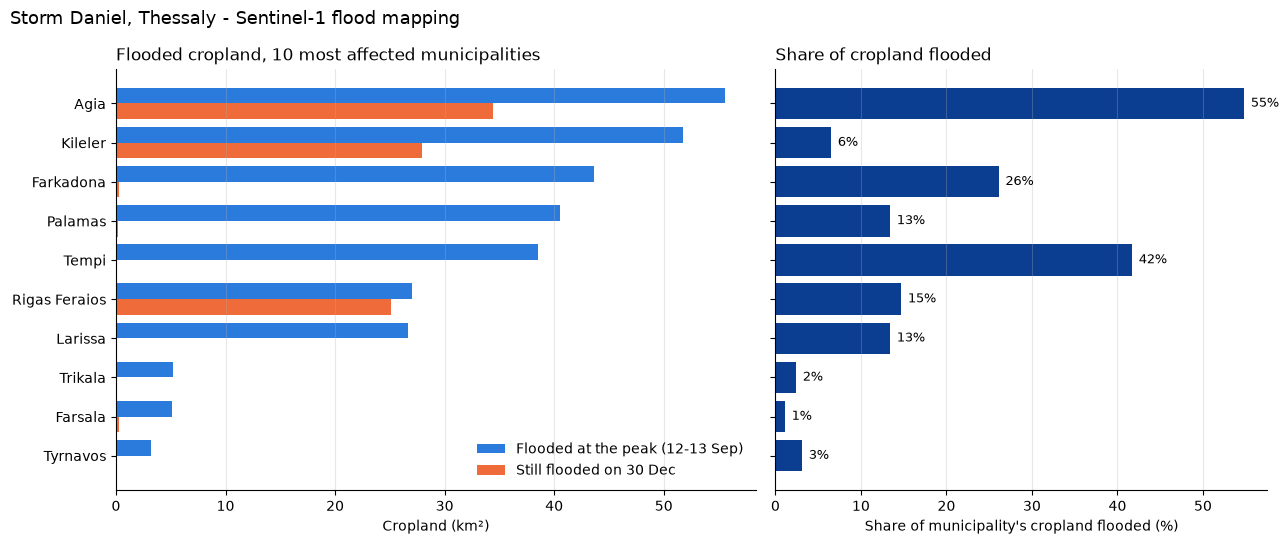

In [3]:
top = df.sort_values(col_peak, ascending=False).head(10)
y = list(range(len(top)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
ax.barh([i - 0.2 for i in y], top[col_peak], height=0.4, color="#2b7bdc", label="Flooded at the peak (12-13 Sep)")
ax.barh([i + 0.2 for i in y], top[col_dec].fillna(0), height=0.4, color="#f06b3a", label="Still flooded on 30 Dec")
ax.set_yticks(y); ax.set_yticklabels(top.index); ax.invert_yaxis()
ax.set_xlabel("Cropland (km²)"); ax.set_title("Flooded cropland, 10 most affected municipalities", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
ax.barh(y, top[col_share], color="#0b3d91")
ax.set_yticks(y); ax.set_yticklabels([]); ax.invert_yaxis()
for i, v in zip(y, top[col_share]):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("Share of municipality's cropland flooded (%)")
ax.set_title("Share of cropland flooded", loc="left")
ax.grid(axis="x", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Storm Daniel, Thessaly - Sentinel-1 flood mapping", fontsize=13, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "summary_figure.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
# Key numbers for the README
if "Total" in raw.index:
    r = raw.loc["Total"]
    print(f"Total flooded:        {r.iloc[0]:.0f} km²")
    print(f"Cropland flooded:     {r[col_peak]:.1f} km² ({r[col_peak]*1000:,.0f} stremmata)")
    print(f"Share of cropland:    {r[col_share]:.1f} %")
    print(f"Still flooded 30 Dec: {r[col_dec]:.1f} km² ({r[col_dec]/r[col_peak]*100:.0f}% of peak cropland)")
print()
print("Main still-flooded municipalities:")
print(df[col_dec].sort_values(ascending=False).head(3))

Total flooded:        341 km²
Cropland flooded:     302.4 km² (302,400 stremmata)
Share of cropland:    9.2 %
Still flooded 30 Dec: 88.7 km² (29% of peak cropland)

Main still-flooded municipalities:
municipality
Agia             34.4
Kileler          27.9
Rigas Feraios    25.1
Name: Cropland still flooded 30 Dec (km²), dtype: float64


In [5]:
# Pre-publish check: project id, credentials, local paths, required files
import json, re

ALLOWED_PID_STRINGS = {"project_id.txt", "your-gcp-project-id"}
secret_patterns = ["private" + "_key", "client" + "_secret", "refresh" + "_token", "AI" + "za", "ya" + "29."]
local_path = re.compile(r"[A-Za-z]:\\{1,4}Users|/Users/|/home/[a-z]")

problems = []
files = sorted(ROOT.glob("notebooks/*.ipynb")) + sorted(ROOT.glob("src/*.py"))
for path in files:
    if path.suffix == ".ipynb":
        nb = json.loads(path.read_text(encoding="utf-8"))
        cells = nb["cells"]
        code = "\n".join("".join(c["source"]) for c in cells if c["cell_type"] == "code")
        outs = json.dumps([c.get("outputs", []) for c in cells if c["cell_type"] == "code"])
    else:
        code, outs = path.read_text(encoding="utf-8"), ""
    own = "PRE-PUBLISH-CHECK" in code      # this notebook contains the patterns it searches for

    for line in code.splitlines():
        if "PROJECT_ID" in line and "=" in line and not own:
            strings = re.findall(r"[\"']([^\"']+)[\"']", line)
            bad = [s for s in strings if s not in ALLOWED_PID_STRINGS]
            if bad:
                problems.append(f"{path.name}: hard-coded project id? -> {bad}")
    if not own:
        for pat in secret_patterns:
            if pat in code or pat in outs:
                problems.append(f"{path.name}: contains '{pat}'")
    if local_path.search(outs):
        problems.append(f"{path.name}: outputs contain a local path (re-run the cell or clear its output)")
    if '"output_type": "error"' in outs.replace("'", '"') or "traceback" in outs.lower():
        problems.append(f"{path.name}: has a cell with an error output")

gi = ROOT / ".gitignore"
if gi.exists():
    lines = gi.read_text(encoding="utf-8", errors="ignore").splitlines()
    if any(l != l.lstrip() for l in lines if l.strip()):
        problems.append(".gitignore has lines that start with a space: Git does not apply those patterns")
    for pattern in [".venv/", "project_id.txt", "*.tif"]:
        if pattern not in [l.strip() for l in lines if l == l.lstrip()]:
            problems.append(f".gitignore does not contain the line {pattern}")
for f in [".gitignore", "LICENSE", "README.md", "requirements.txt"]:
    if not (ROOT / f).exists():
        problems.append(f"{f} is missing in the project root")
for f in ["summary_figure.png", "cropland_flooded_share_map.png"]:
    if not (OUT_DIR / f).exists():
        problems.append(f"outputs/{f} is missing")

print("All good!" if not problems else "\n".join(problems))

All good!
